   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

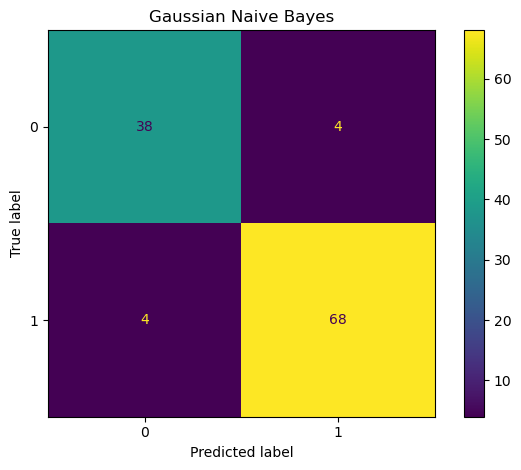

Saved: gaussian_nb.joblib


In [12]:
#Gaussian
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, classification_report,
 confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
data = load_breast_cancer(as_frame=True)
df = data.frame.drop_duplicates().dropna()
X, y = df.drop(columns=["target"]), df["target"]
print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\n", y.value_counts())
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y)
model = Pipeline([("scale", StandardScaler()), ("classifier", GaussianNB())])
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("\nClassification report:\n", classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
print("F1 score:", f1_score(y_test, pred, average="weighted", zero_division=0))
cm = confusion_matrix(y_test, pred)
print("Confusion matrix:\n", cm)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title("Gaussian Naive Bayes")
plt.tight_layout()
plt.show()
joblib.dump(model, "gaussian_nb.joblib")
print("Saved: gaussian_nb.joblib")

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

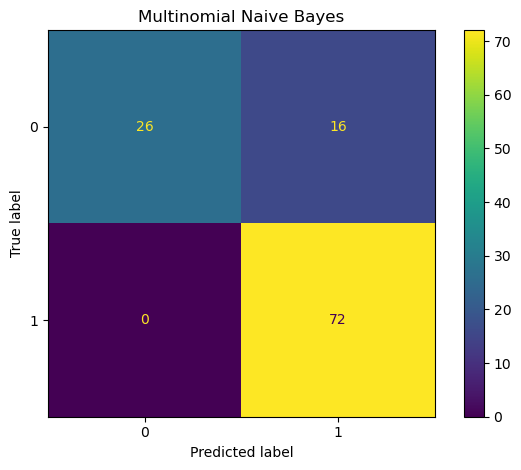

Saved: multinomial_nb.joblib


In [13]:
#Multinomial Naive Bayes
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, classification_report,
 confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
data = load_breast_cancer(as_frame=True)
df = data.frame.drop_duplicates().dropna()
X, y = df.drop(columns=["target"]), df["target"]
print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\n", y.value_counts())
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = MultinomialNB(alpha=1.0)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("\nClassification report:\n", classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
print("F1 score:", f1_score(y_test, pred, average="weighted", zero_division=0))
cm = confusion_matrix(y_test, pred)
print("Confusion matrix:\n", cm)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title("Multinomial Naive Bayes")
plt.tight_layout()
plt.show()
joblib.dump({"model": model, "scaler": scaler}, "multinomial_nb.joblib")
print("Saved: multinomial_nb.joblib")

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

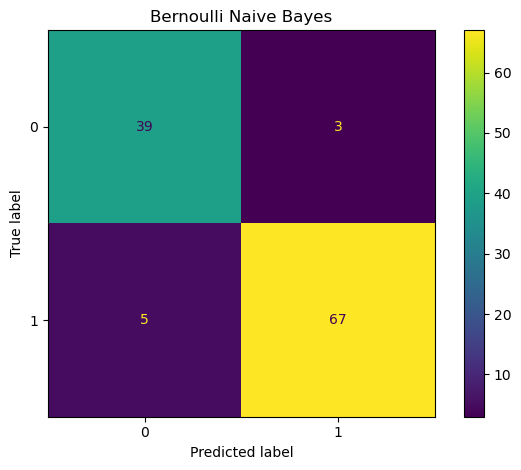

Saved: bernoulli_nb.joblib


In [14]:
#bernoulli
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, Binarizer
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (accuracy_score, classification_report,
 confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
data = load_breast_cancer(as_frame=True)
df = data.frame.drop_duplicates().dropna()
X, y = df.drop(columns=["target"]), df["target"]
print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\n", y.value_counts())
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y)
model = Pipeline([
 ("scale", StandardScaler()),
 ("binary", Binarizer(threshold=0.0)),
 ("classifier", BernoulliNB(alpha=1.0))
])
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("\nClassification report:\n", classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
print("F1 score:", f1_score(y_test, pred, average="weighted", zero_division=0))
cm = confusion_matrix(y_test, pred)
print("Confusion matrix:\n", cm)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title("Bernoulli Naive Bayes")
plt.tight_layout()
plt.show()
joblib.dump(model, "bernoulli_nb.joblib")
print("Saved: bernoulli_nb.joblib")

  mean radius mean texture     target
0        high          low  malignant
1        high          low  malignant
2        high         high  malignant
3         low         high  malignant
4        high          low  malignant
Missing values: 0
Class counts:
 target
benign       357
malignant    212
Name: count, dtype: int64

Classification report:
               precision    recall  f1-score   support

      benign       0.87      0.94      0.91        72
   malignant       0.89      0.76      0.82        42

    accuracy                           0.88       114
   macro avg       0.88      0.85      0.86       114
weighted avg       0.88      0.88      0.87       114

Accuracy: 0.8771929824561403
Confusion matrix (class order ['benign', 'malignant'] ):
 [[68  4]
 [10 32]]


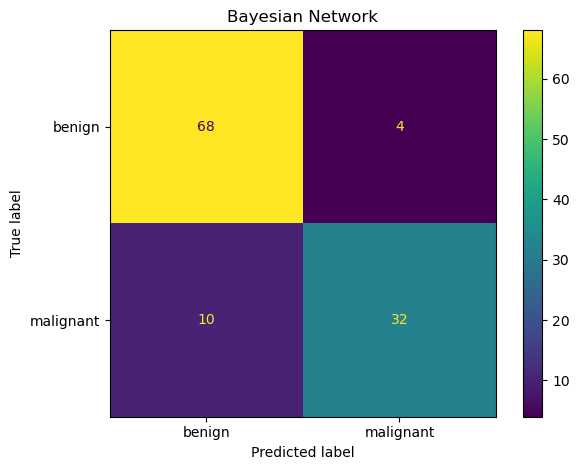

Saved: bayesian_network.joblib


In [16]:
#Bayesian networks
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
df = load_breast_cancer(as_frame=True).frame[
 ["mean radius", "mean texture", "target"]].drop_duplicates().dropna()
df["target"] = df["target"].map({0: "malignant", 1: "benign"})
for col in ["mean radius", "mean texture"]:
 df[col] = pd.qcut(df[col], q=2, labels=["low", "high"]).astype(str)
print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\n", df["target"].value_counts())
train, test = train_test_split(
 df, test_size=0.20, random_state=42, stratify=df["target"])
classes = sorted(train["target"].unique())
features = ["mean radius", "mean texture"]
states = {f: sorted(train[f].unique()) for f in features}
class_counts = train["target"].value_counts().to_dict()
alpha = 1.0
def predict_one(row):
 scores = {}
 for cls in classes:
     subset = train[train["target"] == cls]
     score = (class_counts[cls] + alpha) / (len(train) + alpha * len(classes))
     for f in features:
         count = int((subset[f] == row[f]).sum())
         score *= (count + alpha) / (len(subset) + alpha * len(states[f]))
     scores[cls] = score
 return max(scores, key=scores.get)
pred = [predict_one(row) for _, row in test.iterrows()]
print("\nClassification report:\n", classification_report(test["target"], pred, zero_division=0))
print("Accuracy:", accuracy_score(test["target"], pred))
cm = confusion_matrix(test["target"], pred, labels=classes)
print("Confusion matrix (class order", classes, "):\n", cm)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes).plot()
plt.title("Bayesian Network")
plt.tight_layout()
plt.show()
joblib.dump({"classes": classes, "features": features, "states": states,
 "class_counts": class_counts, "alpha": alpha, "training_data": train},
 "bayesian_network.joblib")
print("Saved: bayesian_network.joblib")